# Detecção de Fraude em Transações de Cartão de Crédito

Neste notebook, vamos construir um pipeline completo para detecção de fraudes, desde a exploração até a explicação das predições com SHAP.

## 1. Importação das Bibliotecas

In [22]:
# === CORREÇÃO DE COMPATIBILIDADE PANDAS >= 2.2 / IPYTHON ===
try:
    import pandas.io.formats.format as _pformat
    if not hasattr(_pformat, 'format_name'):
        def format_name(values, formatter=None, float_format=None, na_rep='NaN', digits=None, space=False, decimal='.'):
            try:
                if hasattr(values, 'name') and values.name is not None:
                    return str(values.name)
            except Exception:
                pass
            return ''
        _pformat.format_name = format_name
    import pandas.io.formats.html as _phtml
    if not hasattr(_phtml, 'format_name'):
        _phtml.format_name = _pformat.format_name
except Exception as _compat_err:
    print('Aviso compatibilidade:', _compat_err)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    roc_auc_score, 
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score
)

from xgboost import XGBClassifier

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

import shap

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

## 2. Carregamento dos Dados

Os dados serão carregados diretamente do Kaggle via URL.

In [23]:
url = 'https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv'
df = pd.read_csv(url)
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Exploração dos Dados

In [24]:
print(f'Shape do dataset: {df.shape}')
df['Class'].value_counts(normalize=True) * 100

Shape do dataset: (284807, 31)


Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

## 4. Preparação dos Dados

In [25]:
df_prep = df.copy()
df_prep['Log_Amount'] = np.log1p(df_prep['Amount'])

X = df_prep.drop('Class', axis=1)
y = df_prep['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
cols_to_scale = ['Time', 'Amount', 'Log_Amount']
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test_scaled[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

## 5. Treinamento dos Modelos

In [26]:
# Regressão Logística - Baseline
lr = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)
y_proba_lr = lr.predict_proba(X_test_scaled)[:, 1]
print('=== REGRESSÃO LOGÍSTICA ===')
print(classification_report(y_test, y_pred_lr, target_names=['Não Fraude', 'Fraude']))

=== REGRESSÃO LOGÍSTICA ===
              precision    recall  f1-score   support

  Não Fraude       1.00      0.98      0.99     56864
      Fraude       0.06      0.92      0.12        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962



In [27]:
# Random Forest
rf = RandomForestClassifier(n_estimators=100, class_weight='balanced_subsample', random_state=42, n_jobs=-1)
rf.fit(X_train_scaled, y_train)
y_pred_rf = rf.predict(X_test_scaled)
y_proba_rf = rf.predict_proba(X_test_scaled)[:, 1]
print('=== RANDOM FOREST ===')
print(classification_report(y_test, y_pred_rf, target_names=['Não Fraude', 'Fraude']))

=== RANDOM FOREST ===
              precision    recall  f1-score   support

  Não Fraude       1.00      1.00      1.00     56864
      Fraude       0.96      0.77      0.85        98

    accuracy                           1.00     56962
   macro avg       0.98      0.88      0.93     56962
weighted avg       1.00      1.00      1.00     56962



In [28]:
# XGBoost
neg, pos = np.bincount(y_train)
scale_pos_weight = neg / pos
xgb = XGBClassifier(n_estimators=100, scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss', n_jobs=-1)
xgb.fit(X_train_scaled, y_train)
y_pred_xgb = xgb.predict(X_test_scaled)
y_proba_xgb = xgb.predict_proba(X_test_scaled)[:, 1]
print('=== XGBOOST ===')
print(classification_report(y_test, y_pred_xgb, target_names=['Não Fraude', 'Fraude']))
print(f'ROC-AUC: {roc_auc_score(y_test, y_proba_xgb):.4f} | PR-AUC: {average_precision_score(y_test, y_proba_xgb):.4f}')

=== XGBOOST ===
              precision    recall  f1-score   support

  Não Fraude       1.00      1.00      1.00     56864
      Fraude       0.87      0.83      0.85        98

    accuracy                           1.00     56962
   macro avg       0.94      0.91      0.92     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC: 0.9726 | PR-AUC: 0.8791


## 6. Comparação com Undersampling e Oversampling

In [29]:
resultados_balance = []

# 1) scale_pos_weight
y_pred_cw = y_pred_xgb
resultados_balance.append({
    'Abordagem': 'XGBoost com scale_pos_weight',
    'Recall (Fraude)': recall_score(y_test, y_pred_cw, pos_label=1),
    'Precisão (Fraude)': precision_score(y_test, y_pred_cw, pos_label=1),
    'F1-Score (Fraude)': f1_score(y_test, y_pred_cw, pos_label=1)
})

# 2) RandomUnderSampler
rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train_scaled, y_train)
xgb_rus = XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss', n_jobs=-1)
xgb_rus.fit(X_train_rus, y_train_rus)
y_pred_rus = xgb_rus.predict(X_test_scaled)
resultados_balance.append({
    'Abordagem': 'XGBoost com RandomUnderSampler',
    'Recall (Fraude)': recall_score(y_test, y_pred_rus, pos_label=1),
    'Precisão (Fraude)': precision_score(y_test, y_pred_rus, pos_label=1),
    'F1-Score (Fraude)': f1_score(y_test, y_pred_rus, pos_label=1)
})

# 3) SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)
xgb_smote = XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss', n_jobs=-1)
xgb_smote.fit(X_train_smote, y_train_smote)
y_pred_smote = xgb_smote.predict(X_test_scaled)
resultados_balance.append({
    'Abordagem': 'XGBoost com SMOTE',
    'Recall (Fraude)': recall_score(y_test, y_pred_smote, pos_label=1),
    'Precisão (Fraude)': precision_score(y_test, y_pred_smote, pos_label=1),
    'F1-Score (Fraude)': f1_score(y_test, y_pred_smote, pos_label=1)
})

pd.DataFrame(resultados_balance).round(4)

,Abordagem,Recall (Fraude),Precisão (Fraude),F1-Score (Fraude)
0,XGBoost com scale_pos_weight,0.8265,0.8710,0.8482
1,XGBoost com RandomUnderSampler,0.9184,0.0341,0.0657
2,XGBoost com SMOTE,0.8469,0.7155,0.7757


## 7. Comparação Geral dos Modelos

In [30]:
resultados = []
for nome, y_pred, y_proba in [
    ('Regressão Logística', y_pred_lr, y_proba_lr),
    ('Random Forest', y_pred_rf, y_proba_rf),
    ('XGBoost', y_pred_xgb, y_proba_xgb)
]:
    resultados.append({
        'Modelo': nome,
        'Recall (Fraude)': recall_score(y_test, y_pred, pos_label=1),
        'Precisão (Fraude)': precision_score(y_test, y_pred, pos_label=1),
        'F1-Score (Fraude)': f1_score(y_test, y_pred, pos_label=1),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
        'PR-AUC': average_precision_score(y_test, y_proba)
    })
pd.DataFrame(resultados).round(4)

,Modelo,Recall (Fraude),Precisão (Fraude),F1-Score (Fraude),ROC-AUC,PR-AUC
0,Regressão Logística,0.9184,0.0614,0.1151,0.9719,0.7164
1,Random Forest,0.7653,0.9615,0.8523,0.9478,0.8670
2,XGBoost,0.8265,0.8710,0.8482,0.9726,0.8791


## 8. Ajuste do Limiar de Decisão (XGBoost)

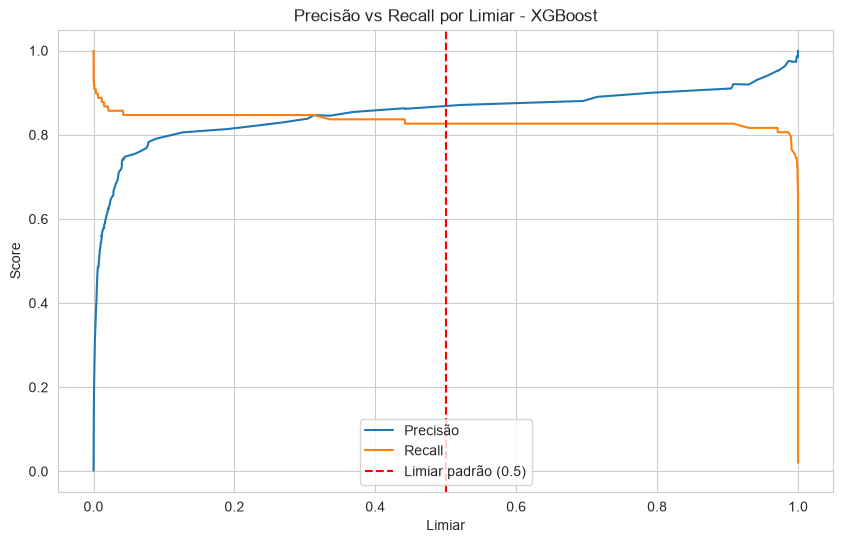

In [31]:
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba_xgb)
plt.figure(figsize=(10,6))
plt.plot(thresholds, precisions[:-1], label='Precisão')
plt.plot(thresholds, recalls[:-1], label='Recall')
plt.axvline(x=0.5, color='red', linestyle='--', label='Limiar padrão (0.5)')
plt.title('Precisão vs Recall por Limiar - XGBoost')
plt.xlabel('Limiar')
plt.ylabel('Score')
plt.legend()
plt.grid(True)
plt.show()

In [32]:
for thresh in [0.3, 0.4, 0.5]:
    y_pred_thresh = (y_proba_xgb >= thresh).astype(int)
    print(f'\n=== LIMIAR = {thresh} ===')
    print(f'Recall: {recall_score(y_test, y_pred_thresh, pos_label=1):.4f} | Precisão: {precision_score(y_test, y_pred_thresh, pos_label=1):.4f} | F1: {f1_score(y_test, y_pred_thresh, pos_label=1):.4f}')


=== LIMIAR = 0.3 ===
Recall: 0.8469 | Precisão: 0.8384 | F1: 0.8426

=== LIMIAR = 0.4 ===
Recall: 0.8367 | Precisão: 0.8632 | F1: 0.8497

=== LIMIAR = 0.5 ===
Recall: 0.8265 | Precisão: 0.8710 | F1: 0.8482


In [33]:
thresh_escolhido = 0.4
y_pred_final = (y_proba_xgb >= thresh_escolhido).astype(int)
print(f'=== XGBOOST COM LIMIAR = {thresh_escolhido} ===')
print(classification_report(y_test, y_pred_final, target_names=['Não Fraude', 'Fraude']))
print(confusion_matrix(y_test, y_pred_final))

=== XGBOOST COM LIMIAR = 0.4 ===
              precision    recall  f1-score   support

  Não Fraude       1.00      1.00      1.00     56864
      Fraude       0.86      0.84      0.85        98

    accuracy                           1.00     56962
   macro avg       0.93      0.92      0.92     56962
weighted avg       1.00      1.00      1.00     56962

[[56851    13]
 [   16    82]]


## 9. Explicabilidade com SHAP

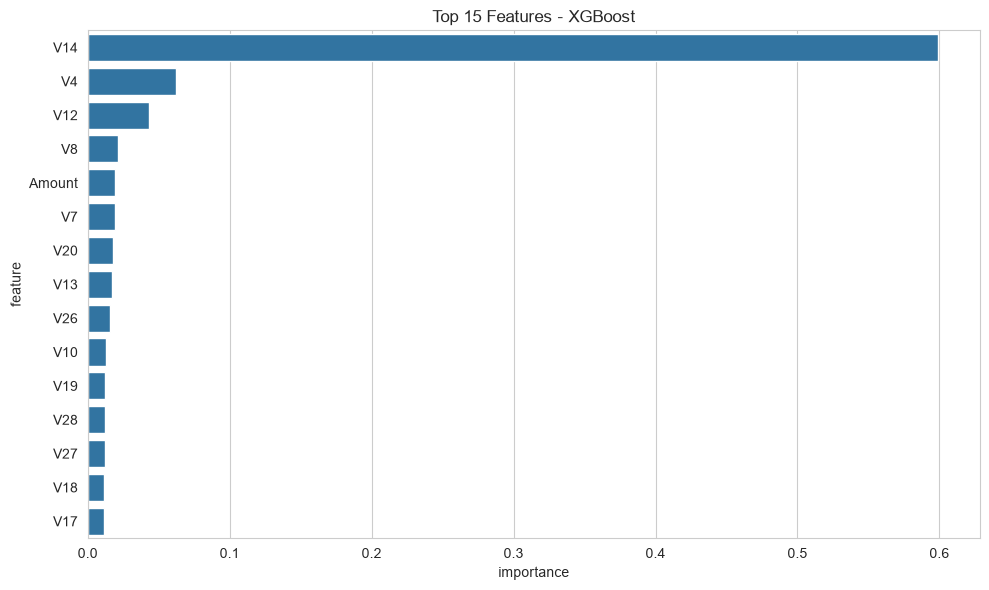

In [34]:
feat_importance = pd.DataFrame({
    'feature': X_train_scaled.columns,
    'importance': xgb.feature_importances_
}).sort_values('importance', ascending=False).head(15)
plt.figure(figsize=(10,6))
sns.barplot(data=feat_importance, x='importance', y='feature')
plt.title('Top 15 Features - XGBoost')
plt.tight_layout()
plt.show()

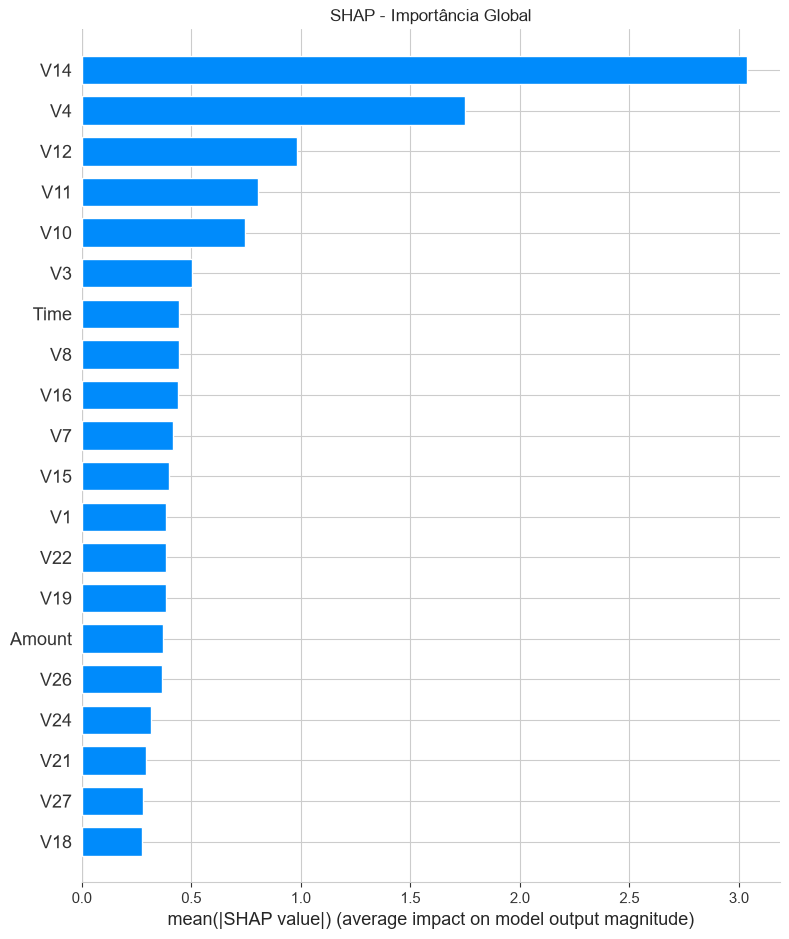

In [35]:
explainer = shap.TreeExplainer(xgb)
X_test_sample = X_test_scaled.sample(1000, random_state=42)
shap_values = explainer.shap_values(X_test_sample)
shap.summary_plot(shap_values, X_test_sample, plot_type='bar', show=False)
plt.title('SHAP - Importância Global')
plt.tight_layout()
plt.show()

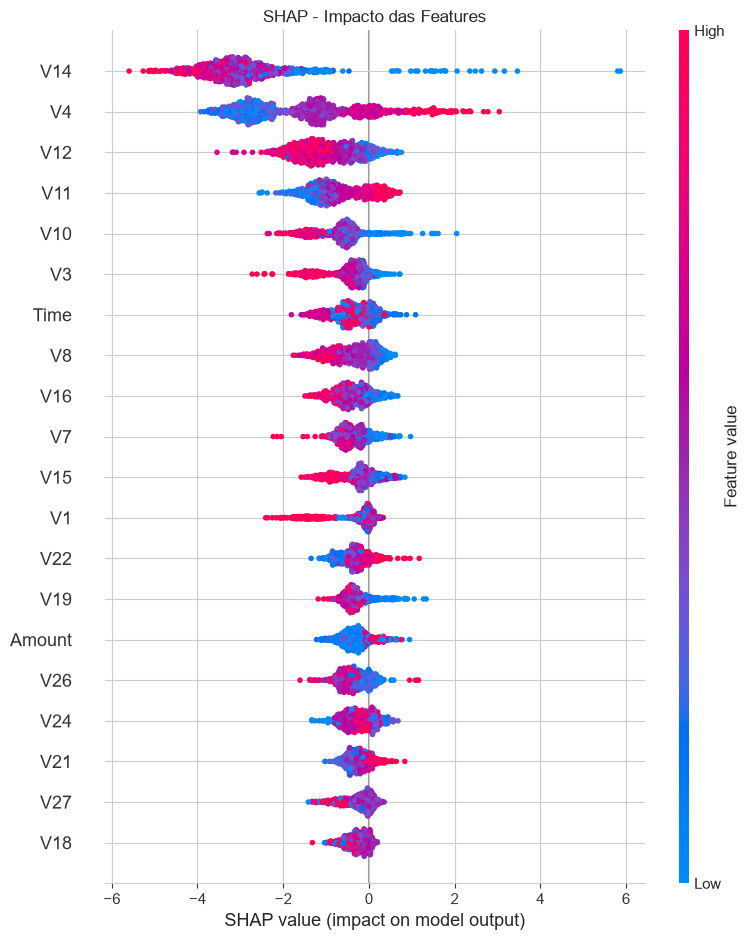

In [36]:
shap.summary_plot(shap_values, X_test_sample, show=False)
plt.title('SHAP - Impacto das Features')
plt.tight_layout()
plt.show()

## 10. Conclusão

- **Desbalanceamento:** Com apenas 0,17% de fraudes, acurácia é enganosa. Priorizamos Recall, Precisão, F1 e PR-AUC.
- **Balanceamento:** Comparação entre `class_weight`/`scale_pos_weight`, `RandomUnderSampler` e `SMOTE` mostrou diferentes trade-offs entre recall e precisão.
- **Melhor abordagem:** XGBoost com `scale_pos_weight` apresentou bom equilíbrio. Com ajuste de limiar para 0.4, foi possível melhorar o recall da classe fraude.
- **Explicabilidade:** SHAP e feature importance mostram que os componentes V gerados por PCA são os principais preditores, coerente com o objetivo de proteger a privacidade dos dados.